# Resultados del analisis internacional
Consolida los hallazgos de EDA, calidad, temporalidad, comparacion de fuentes y TSI provisional.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'data').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
RESULTS = PROJECT_ROOT / 'data' / '03_analysis_output'
profile = json.loads((RESULTS / 'eda' / 'perfil_global.json').read_text(encoding='utf-8'))
quality = json.loads((RESULTS / 'calidad_cobertura' / 'calidad_global.json').read_text(encoding='utf-8'))
comparison = pd.read_csv(RESULTS / 'comparacion_fuentes' / 'matriz_comparabilidad.csv')
tsi = pd.read_csv(RESULTS / 'indicador_tsi' / 'tsi_provisional_diario.csv')
print(profile)
print(quality)

{'filas': 41770880, 'grupos_ciudad_fuente_metrica': 5, 'timestamp_minimo': '2001-01-02T07:30:00', 'timestamp_maximo': '2024-10-18T00:00:00', 'batch_size': 250000, 'max_rows': None, 'input': 'C:\\Users\\REYES\\OneDrive\\Desktop\\terminado\\portafolio data science\\TSI\\data\\02_clean\\consolidated\\international_observations.parquet'}
{'filas_evaluadas': 41770880, 'grupos_evaluados': 5, 'controles_de_rango': {'latitud_fuera_rango': 0, 'longitud_fuera_rango': 0, 'periodo_no_positivo': 0, 'timestamp_invalido': 0, 'valor_fuente_negativo': 0, 'valor_principal_negativo': 0}, 'input': 'C:\\Users\\REYES\\OneDrive\\Desktop\\terminado\\portafolio data science\\TSI\\data\\02_clean\\consolidated\\international_observations.parquet', 'max_rows': None}


In [2]:
findings = comparison[['fuente', 'metrica_principal', 'familia_metrica', 'unidad_conceptual', 'comparacion_directa', 'condicion_comparacion']]
display(findings)
tsi_summary = tsi.groupby('fuente', as_index=False).agg(
    dias=('fecha', 'nunique'),
    media_tsi=('tsi_provisional_media', 'mean'),
    observaciones=('observaciones', 'sum'),
)
display(tsi_summary.sort_values('media_tsi', ascending=False))

,fuente,metrica_principal,familia_metrica,unidad_conceptual,comparacion_directa,condicion_comparacion
0,sao_paulo_cet,congestion_longitud_m,congestion_longitud,longitud congestionada,False,no comparar en escala original
1,istanbul_traffic_index,indice_congestion,indice_congestion,indice relativo,False,no comparar en escala original
2,madrid_traffic_points,intensidad,intensidad,intensidad de trafico,False,no comparar en escala original
3,metr_la,velocidad_sensor,velocidad,velocidad de sensor,True,verificar unidad y alinear ventana temporal
4,pems_bay,velocidad_sensor,velocidad,velocidad de sensor,True,verificar unidad y alinear ventana temporal


,fuente,dias,media_tsi,observaciones
1,madrid_traffic_points,31,98.609834,12512133
4,sao_paulo_cet,6094,94.243199,5223411
2,metr_la,119,76.741459,7094304
3,pems_bay,181,73.584399,16937700
0,istanbul_traffic_index,3332,54.157017,3332


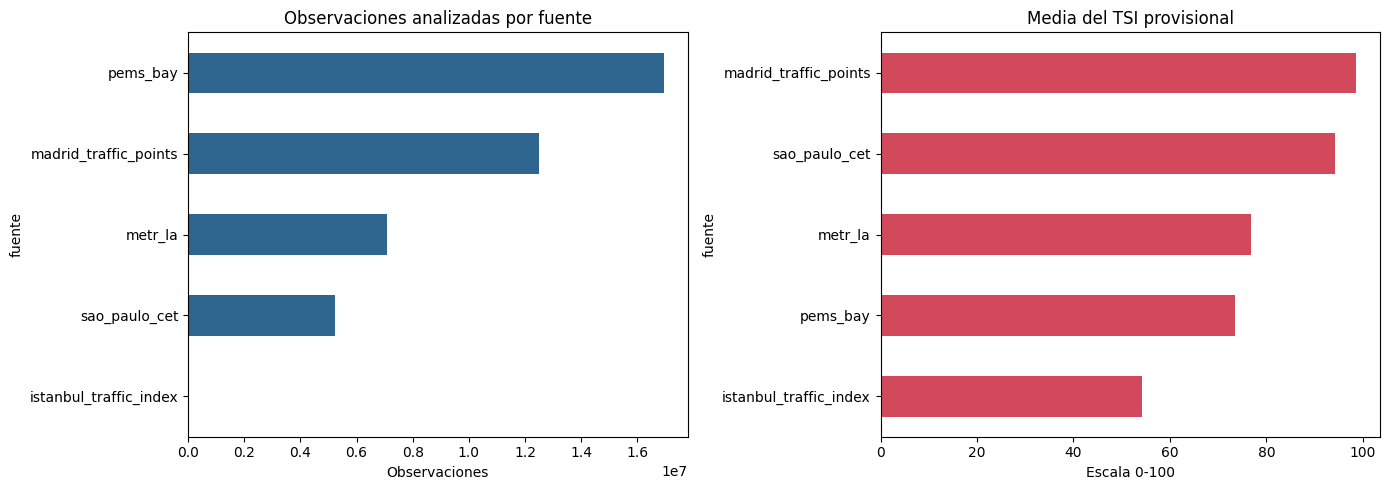

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tsi_summary.sort_values('observaciones').plot.barh(x='fuente', y='observaciones', ax=axes[0], legend=False, color='#2f6690')
axes[0].set_title('Observaciones analizadas por fuente')
axes[0].set_xlabel('Observaciones')
tsi_summary.sort_values('media_tsi').plot.barh(x='fuente', y='media_tsi', ax=axes[1], legend=False, color='#d1495b')
axes[1].set_title('Media del TSI provisional')
axes[1].set_xlabel('Escala 0-100')
plt.tight_layout()
plt.show()

## Conclusiones de alcance
Las fuentes no se combinan en una escala original comun. METR-LA y PEMS-BAY comparten familia de velocidad, mientras que Istanbul, Madrid y Sao Paulo requieren interpretacion separada. El TSI mostrado es provisional y sirve como insumo para la siguiente fase experimental.